# Signal Filtering Assignment — Rizwan (BSAI23004)

This notebook implements the code-based portion of the assignment.



## 1. Imports and setup

In [200]:
import os
from pathlib import Path
from math import gcd

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

# Change these filenames if needed
WHISPER_FILE = "whisper.wav"
RUMBLE_FILE = "low_rumble.wav"

PREFIX = "Rizwan_BSAI23004"

OUTPUT_DIR = Path("assignment_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

FIXED_CUTOFF = 300.0

# Set your chosen cutoff after inspecting the spectrum
OPTIMAL_CUTOFF = 1000

## 2. Audio helper functions

In [201]:
def to_mono(x):
    x = np.asarray(x)
    if x.ndim == 1:
        return x.astype(np.float64)
    return x.mean(axis=1).astype(np.float64)


def normalize_peak(x):
    x = np.asarray(x, dtype=np.float64)
    peak = np.max(np.abs(x))
    if peak == 0:
        return x.copy()
    return x / peak


def read_audio(path):
    sr, data = wavfile.read(path)
    return int(sr), to_mono(data)


def resample_audio(x, old_sr, new_sr):
    if old_sr == new_sr:
        return x
    g = gcd(int(old_sr), int(new_sr))
    up = new_sr // g
    down = old_sr // g
    return resample_poly(x, up, down)


def match_lengths(a, b):
    n = min(len(a), len(b))
    return a[:n], b[:n]


def write_wav(path, sr, x):
    x = normalize_peak(x)
    pcm = np.int16(np.clip(x, -1, 1) * 32767)
    wavfile.write(str(path), sr, pcm)

## 3. Load the audio files

In [202]:
if not Path(WHISPER_FILE).exists():
    raise FileNotFoundError(
        f"{WHISPER_FILE} was not found. Upload your whisper/whistle WAV file first."
    )

if not Path(RUMBLE_FILE).exists():
    raise FileNotFoundError(
        f"{RUMBLE_FILE} was not found. Upload low_rumble.wav first."
    )

whisper_sr, whisper = read_audio(WHISPER_FILE)
rumble_sr, rumble = read_audio(RUMBLE_FILE)

print("Whisper/whistle")
print("Sampling rate:", whisper_sr, "Hz")
print("Samples:", len(whisper))
print("Duration:", len(whisper) / whisper_sr, "seconds")
print()
print("Low rumble")
print("Sampling rate:", rumble_sr, "Hz")
print("Samples:", len(rumble))
print("Duration:", len(rumble) / rumble_sr, "seconds")

Whisper/whistle
Sampling rate: 48000 Hz
Samples: 314368
Duration: 6.549333333333333 seconds

Low rumble
Sampling rate: 44100 Hz
Samples: 220500
Duration: 5.0 seconds


/tmp/ipykernel_69746/3280936032.py:17: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, data = wavfile.read(path)


## 4. Match sampling rates and lengths

In [203]:
target_sr = whisper_sr

if rumble_sr != target_sr:
    print(f"Resampling rumble from {rumble_sr} Hz to {target_sr} Hz")
    rumble = resample_audio(rumble, rumble_sr, target_sr)

whisper, rumble = match_lengths(whisper, rumble)

print("Common sampling rate:", target_sr, "Hz")
print("Number of samples:", len(whisper))
print("Duration:", len(whisper) / target_sr, "seconds")

Resampling rumble from 44100 Hz to 48000 Hz
Common sampling rate: 48000 Hz
Number of samples: 240000
Duration: 5.0 seconds


## 5. Normalize and mix the signals

In [204]:
whisper_norm = normalize_peak(whisper)
rumble_norm = normalize_peak(rumble)

mixture = whisper_norm + rumble_norm
mixture = normalize_peak(mixture)

print("Whisper peak:", np.max(np.abs(whisper_norm)))
print("Rumble peak:", np.max(np.abs(rumble_norm)))
print("Mixture peak:", np.max(np.abs(mixture)))

Whisper peak: 1.0
Rumble peak: 1.0
Mixture peak: 1.0


In [205]:
mixed_path = OUTPUT_DIR / f"{PREFIX}_mixed.wav"
write_wav(mixed_path, target_sr, mixture)
print("Saved:", mixed_path)

Saved: assignment_outputs/Rizwan_BSAI23004_mixed.wav


## 6. Listen to the signals

In [206]:
print("Whisper / whistle:")
display(Audio(whisper_norm, rate=target_sr))

print("Low rumble:")
display(Audio(rumble_norm, rate=target_sr))

print("Mixed signal:")
display(Audio(mixture, rate=target_sr))

Whisper / whistle:


Low rumble:


Mixed signal:


## 7. Calculate the FFT

In [207]:
def centered_spectrum(x, sr):
    N = len(x)
    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1 / sr)
    X_shifted = np.fft.fftshift(X)
    freqs_shifted = np.fft.fftshift(freqs)
    magnitude = np.abs(X_shifted) / N
    return freqs_shifted, magnitude, X

freqs, magnitude, X = centered_spectrum(mixture, target_sr)

## 8. Plot 1 — Mixed signal spectrum

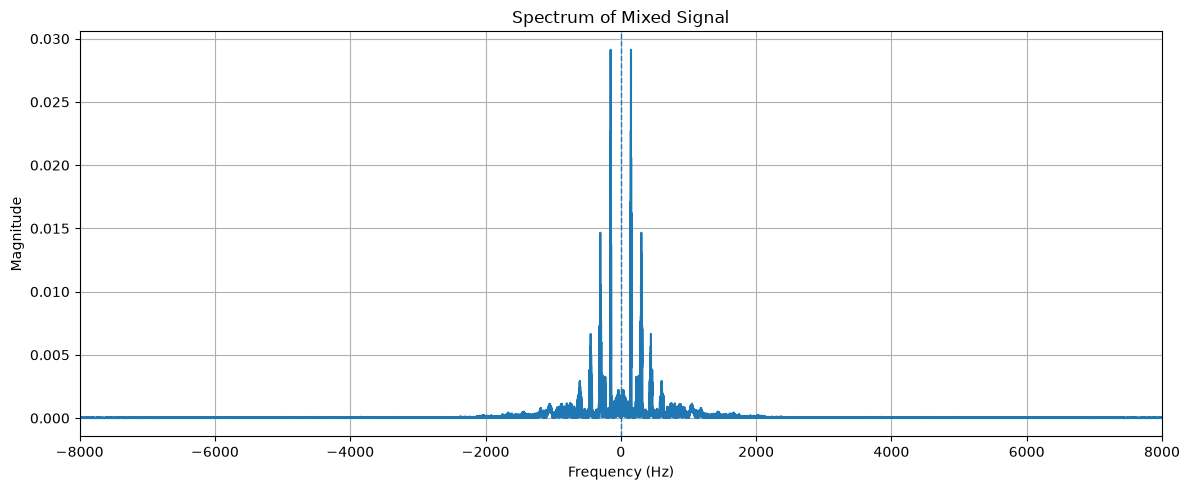

Saved: assignment_outputs/Rizwan_BSAI23004_Plot1.png


In [208]:
plt.figure(figsize=(12, 5))
plt.plot(freqs, magnitude)
plt.title("Spectrum of Mixed Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")

max_display_frequency = min(target_sr / 2, 8000)
plt.xlim(-max_display_frequency, max_display_frequency)
plt.axvline(0, linestyle="--", linewidth=1)
plt.tight_layout()

# Required output: Rizwan_BSAI23004_Plot1.png
spectrum_path = OUTPUT_DIR / f"{PREFIX}_Plot1.png"
plt.savefig(spectrum_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", spectrum_path)

## 9. Ideal LPF and HPF

The LPF keeps frequencies where `|f| <= cutoff`.  
The HPF keeps frequencies where `|f| >= cutoff`.

In [209]:
def ideal_lpf(x, sr, cutoff):
    N = len(x)
    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1 / sr)
    mask = np.abs(freqs) <= cutoff
    X_filtered = X * mask
    return np.fft.ifft(X_filtered).real


def ideal_hpf(x, sr, cutoff):
    N = len(x)
    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1 / sr)
    mask = np.abs(freqs) >= cutoff
    X_filtered = X * mask
    return np.fft.ifft(X_filtered).real

## 10. Plot filter results helper

In [210]:
def plot_filter_result(original, filtered, sr, cutoff, filter_name, filename):
    N = len(filtered)
    time = np.arange(N) / sr
    f, mag, _ = centered_spectrum(filtered, sr)

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    display_seconds = min(0.1, N / sr)
    display_samples = max(1, int(display_seconds * sr))

    axes[0].plot(time[:display_samples], original[:display_samples], label="Original mixture")
    axes[0].plot(time[:display_samples], filtered[:display_samples], label=f"{filter_name} output")
    axes[0].set_title(f"{filter_name} — Time Domain")
    axes[0].set_xlabel("Time (seconds)")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend()

    axes[1].plot(f, mag)
    axes[1].axvline(cutoff, linestyle="--", label=f"+{cutoff:g} Hz")
    axes[1].axvline(-cutoff, linestyle="--", label=f"-{cutoff:g} Hz")
    axes[1].set_title(f"{filter_name} — Output Spectrum")
    axes[1].set_xlabel("Frequency (Hz)")
    axes[1].set_ylabel("Magnitude")

    max_display_frequency = min(sr / 2, 8000)
    axes[1].set_xlim(-max_display_frequency, max_display_frequency)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

## 11. Apply the fixed 300 Hz filters

In [211]:
fixed_cutoff = 300.0

fixed_lpf = normalize_peak(ideal_lpf(mixture, target_sr, fixed_cutoff))
fixed_hpf = normalize_peak(ideal_hpf(mixture, target_sr, fixed_cutoff))

In [212]:
# Required outputs: {PREFIX}_mixed_fixed_lpf.wav / _hpf.wav
fixed_lpf_wav = OUTPUT_DIR / f"{PREFIX}_mixed_fixed_lpf.wav"
fixed_hpf_wav = OUTPUT_DIR / f"{PREFIX}_mixed_fixed_hpf.wav"

write_wav(fixed_lpf_wav, target_sr, fixed_lpf)
write_wav(fixed_hpf_wav, target_sr, fixed_hpf)

print("Saved:", fixed_lpf_wav)
print("Saved:", fixed_hpf_wav)

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_fixed_lpf.wav
Saved: assignment_outputs/Rizwan_BSAI23004_mixed_fixed_hpf.wav


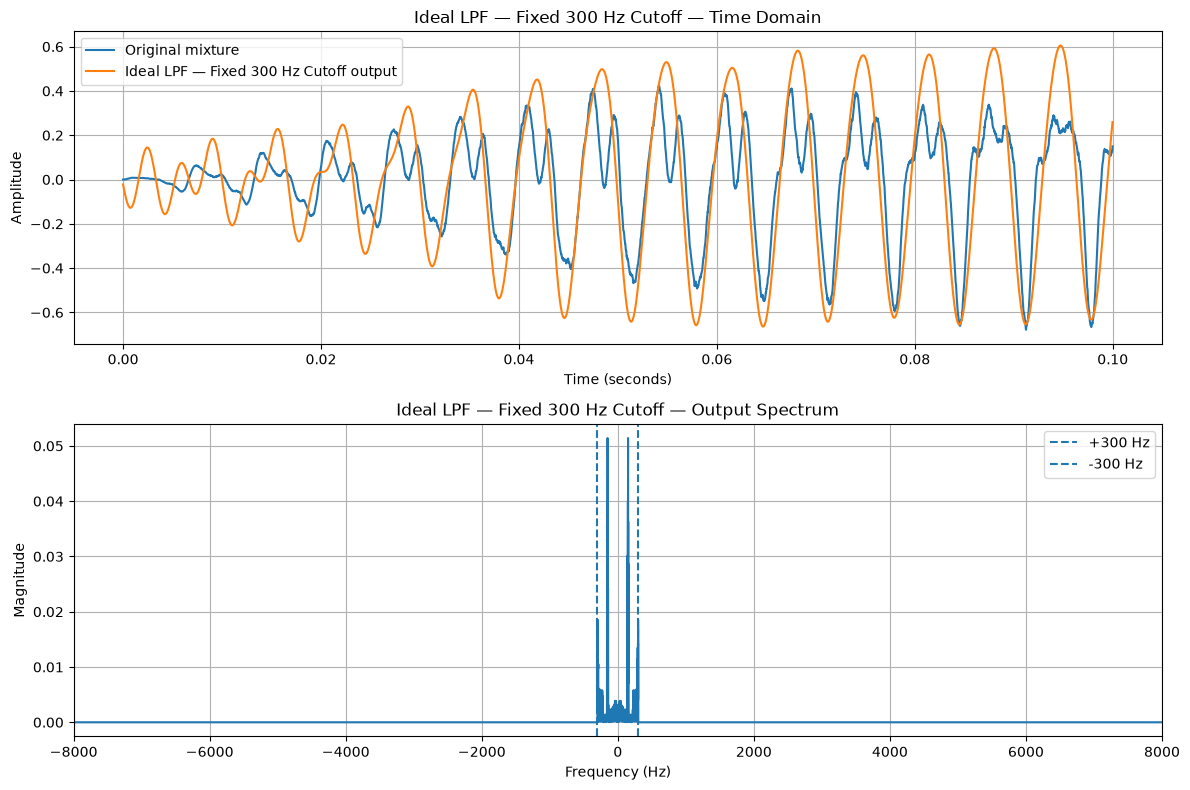

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_fixed_lpf.png


In [213]:
# Plot 2 — Fixed LPF  (required: {PREFIX}_mixed_fixed_lpf.png)
fixed_lpf_plot = OUTPUT_DIR / f"{PREFIX}_mixed_fixed_lpf.png"
plot_filter_result(mixture, fixed_lpf, target_sr, fixed_cutoff,
                   "Ideal LPF — Fixed 300 Hz Cutoff", fixed_lpf_plot)
print("Saved:", fixed_lpf_plot)

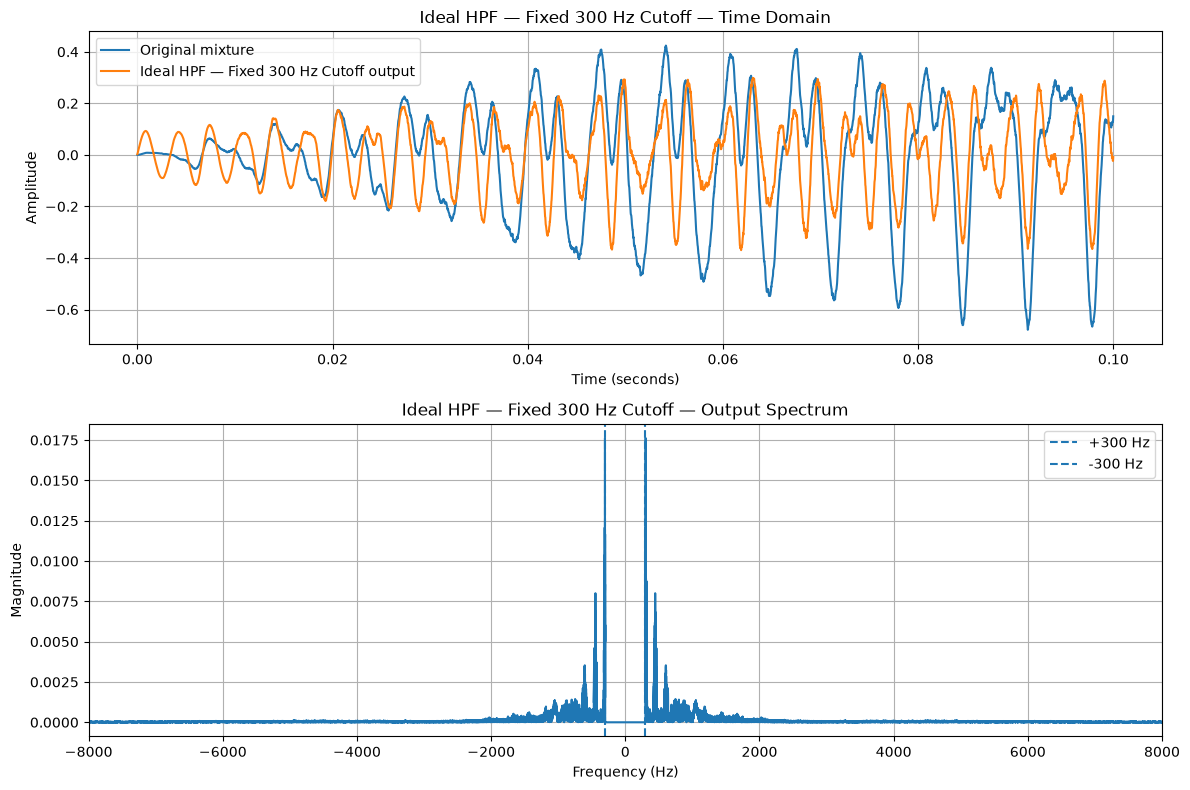

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_fixed_hpf.png


In [214]:
# Plot 3 — Fixed HPF  (required: {PREFIX}_mixed_fixed_hpf.png)
fixed_hpf_plot = OUTPUT_DIR / f"{PREFIX}_mixed_fixed_hpf.png"
plot_filter_result(mixture, fixed_hpf, target_sr, fixed_cutoff,
                   "Ideal HPF — Fixed 300 Hz Cutoff", fixed_hpf_plot)
print("Saved:", fixed_hpf_plot)

## 12. Listen to the fixed-cutoff outputs

In [215]:
print("Fixed 300 Hz LPF:")
display(Audio(fixed_lpf, rate=target_sr))

print("Fixed 300 Hz HPF:")
display(Audio(fixed_hpf, rate=target_sr))

Fixed 300 Hz LPF:


Fixed 300 Hz HPF:


## 13. Inspect the spectrum — choose an optimal cutoff

Run the cell below, look at where the energy separates, and update `OPTIMAL_CUTOFF` in the next cell.

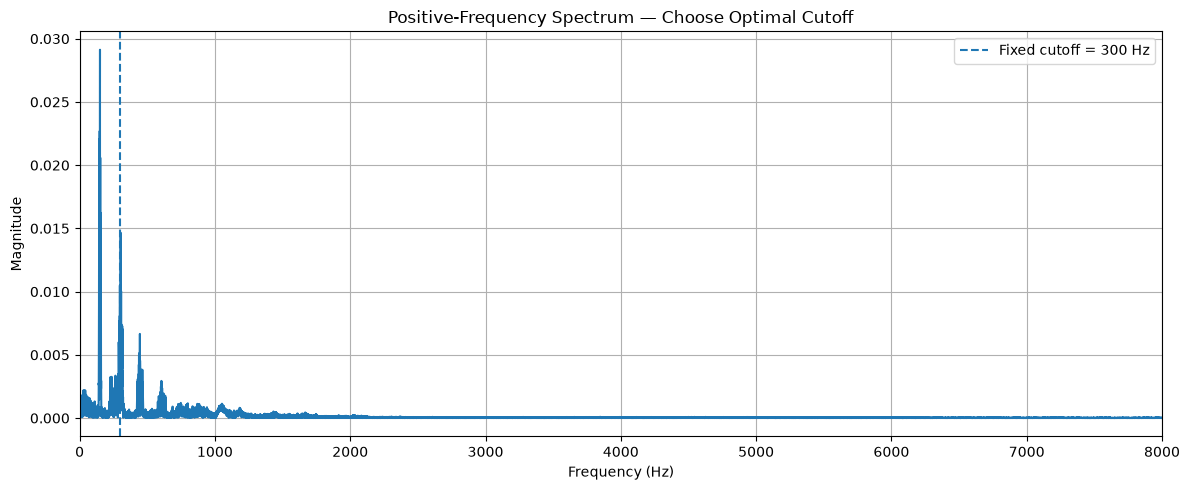

In [216]:
positive = freqs >= 0
f_positive = freqs[positive]
m_positive = magnitude[positive]

plt.figure(figsize=(12, 5))
plt.plot(f_positive, m_positive)
plt.title("Positive-Frequency Spectrum — Choose Optimal Cutoff")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, min(target_sr / 2, 8000))
plt.axvline(300, linestyle="--", label="Fixed cutoff = 300 Hz")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Set the optimal cutoff

Inspect the spectrum above, then set your chosen value below (do **not** blindly use 500 Hz).

In [217]:
# ← Change this to your chosen cutoff
OPTIMAL_CUTOFF = 700
optimal_cutoff = float(OPTIMAL_CUTOFF)
print("Chosen optimal cutoff:", optimal_cutoff, "Hz")

Chosen optimal cutoff: 700.0 Hz


In [218]:
optimal_lpf = normalize_peak(ideal_lpf(mixture, target_sr, optimal_cutoff))
optimal_hpf = normalize_peak(ideal_hpf(mixture, target_sr, optimal_cutoff))

In [219]:
# Required outputs: {PREFIX}_mixed_optimal_lpf.wav / _hpf.wav
optimal_lpf_wav = OUTPUT_DIR / f"{PREFIX}_mixed_optimal_lpf.wav"
optimal_hpf_wav = OUTPUT_DIR / f"{PREFIX}_mixed_optimal_hpf.wav"

write_wav(optimal_lpf_wav, target_sr, optimal_lpf)
write_wav(optimal_hpf_wav, target_sr, optimal_hpf)

print("Saved:", optimal_lpf_wav)
print("Saved:", optimal_hpf_wav)

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_optimal_lpf.wav
Saved: assignment_outputs/Rizwan_BSAI23004_mixed_optimal_hpf.wav


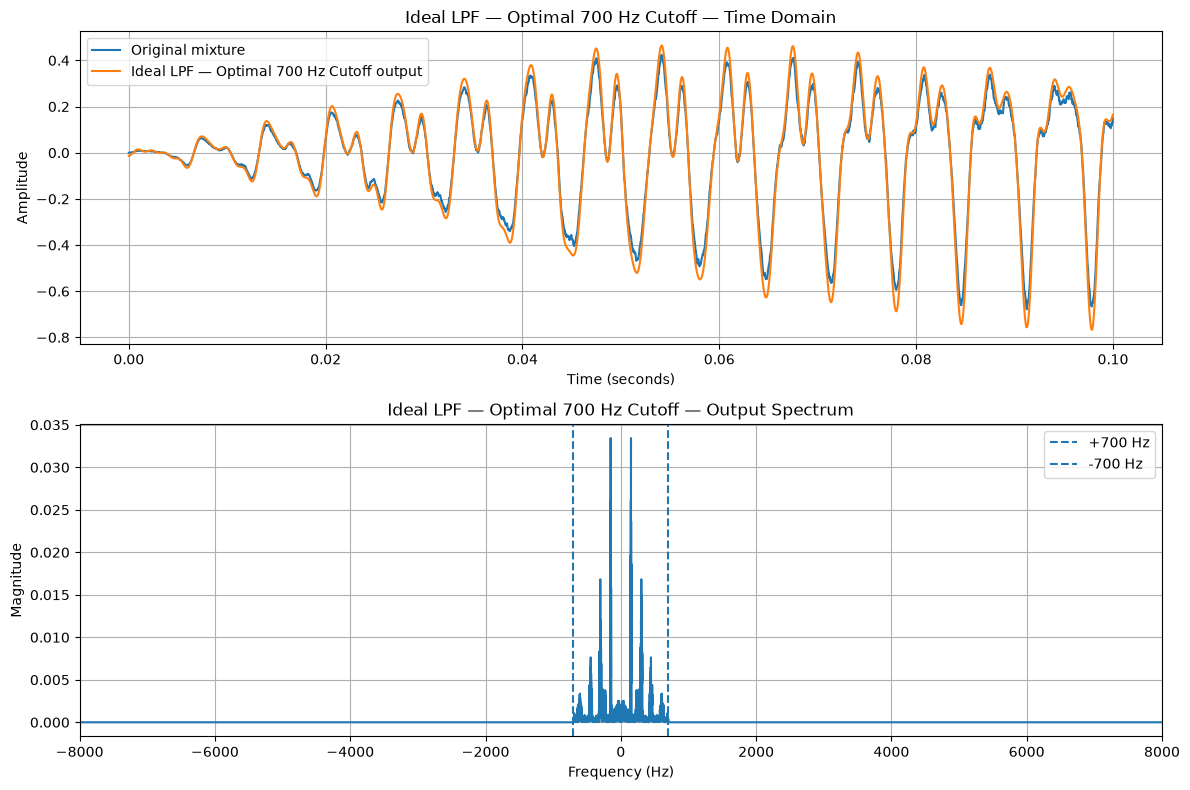

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_optimal_lpf.png


In [220]:
# Plot 4 — Optimal LPF  (required: {PREFIX}_mixed_optimal_lpf.png)
optimal_lpf_plot = OUTPUT_DIR / f"{PREFIX}_mixed_optimal_lpf.png"
plot_filter_result(mixture, optimal_lpf, target_sr, optimal_cutoff,
                   f"Ideal LPF — Optimal {optimal_cutoff:g} Hz Cutoff", optimal_lpf_plot)
print("Saved:", optimal_lpf_plot)

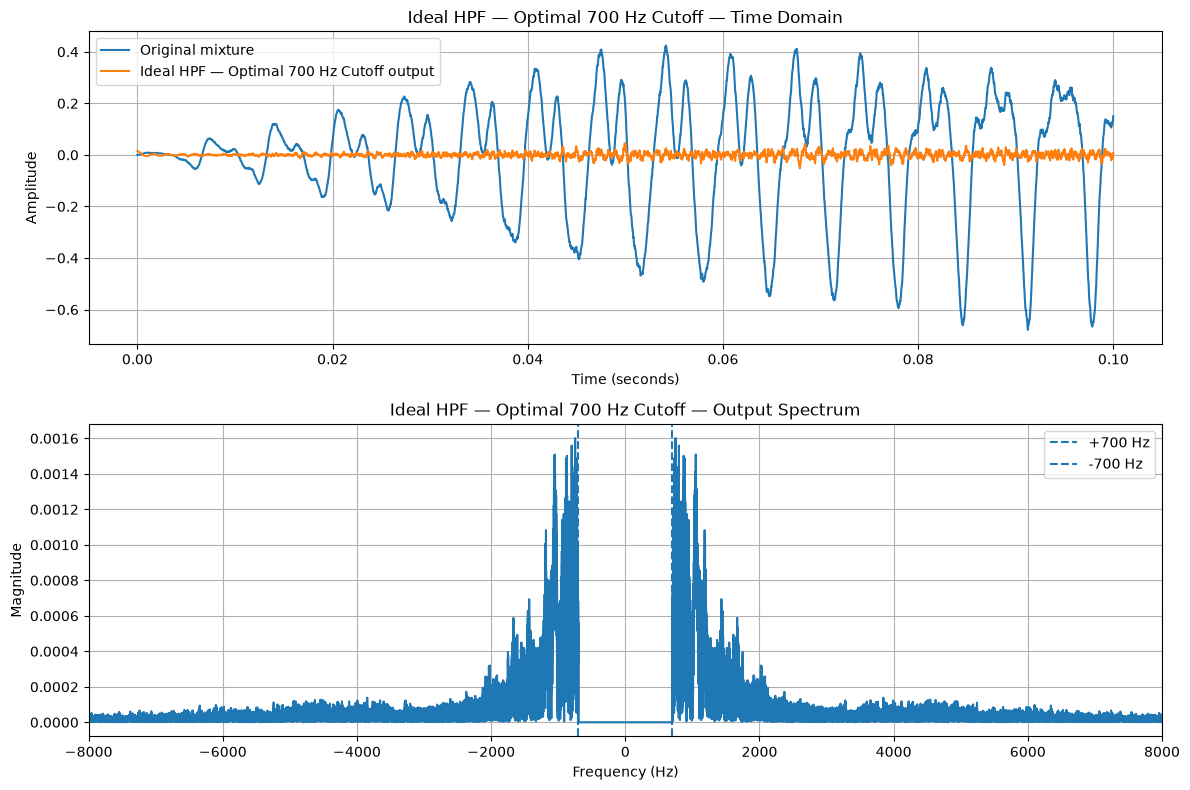

Saved: assignment_outputs/Rizwan_BSAI23004_mixed_optimal_hpf.png


In [221]:
# Plot 5 — Optimal HPF  (required: {PREFIX}_mixed_optimal_hpf.png)
optimal_hpf_plot = OUTPUT_DIR / f"{PREFIX}_mixed_optimal_hpf.png"
plot_filter_result(mixture, optimal_hpf, target_sr, optimal_cutoff,
                   f"Ideal HPF — Optimal {optimal_cutoff:g} Hz Cutoff", optimal_hpf_plot)
print("Saved:", optimal_hpf_plot)

## 15. Listen to the optimal-cutoff outputs

In [222]:
print(f"Optimal LPF ({optimal_cutoff:g} Hz):")
display(Audio(optimal_lpf, rate=target_sr))

print(f"Optimal HPF ({optimal_cutoff:g} Hz):")
display(Audio(optimal_hpf, rate=target_sr))

Optimal LPF (700 Hz):


Optimal HPF (700 Hz):


## 16. Optimal cutoff reasoning

Replace this text with your actual observations.

I selected approximately **700
 Hz** as the optimal cutoff because most of the low-frequency rumble energy was concentrated below this region, while the higher-frequency whisper/whistle energy was more prominent above it.  
This provided better separation than the fixed 300 Hz cutoff.  
Listening to the filtered outputs confirmed that the HPF retained the high-frequency component while the LPF retained the rumble.

## 17. Part A observations

1. The fixed 300 Hz cutoff separated much of the low-frequency rumble from the higher-frequency whisper/whistle.
2. The optimal cutoff was selected by examining the mixed spectrum.
3. The ideal LPF retained the low-frequency rumble; the ideal HPF retained the higher-frequency component.

## 18. Required output files

All files are saved in `assignment_outputs/`:

| File | Description |
|---|---|
| `Rizwan_BSAI23004_Plot1.png` | Mixed signal spectrum |
| `Rizwan_BSAI23004_mixed.wav` | Mixed audio |
| `Rizwan_BSAI23004_mixed_fixed_lpf.wav` | Fixed 300 Hz LPF audio |
| `Rizwan_BSAI23004_mixed_fixed_lpf.png` | Fixed LPF plot |
| `Rizwan_BSAI23004_mixed_fixed_hpf.wav` | Fixed 300 Hz HPF audio |
| `Rizwan_BSAI23004_mixed_fixed_hpf.png` | Fixed HPF plot |
| `Rizwan_BSAI23004_mixed_optimal_lpf.wav` | Optimal LPF audio |
| `Rizwan_BSAI23004_mixed_optimal_lpf.png` | Optimal LPF plot |
| `Rizwan_BSAI23004_mixed_optimal_hpf.wav` | Optimal HPF audio |
| `Rizwan_BSAI23004_mixed_optimal_hpf.png` | Optimal HPF plot |

